# 04 · Driver regression (Phase 4)

**Goal:** which conditions come before premium rises, in plain-English effect sizes — what should a dealer watch? This also checks the features used by the Phase 5 quantile regression.

**Model:** pooled OLS of the 2-round % rise across Cat A, B, E with category and round dummies. **HAC (Newey–West) standard errors with maxlags = h = 2**, because consecutive 2-round rises overlap by one round, so their errors are correlated and ordinary standard errors would be too small.

These are **associations, not causes**: dealers' own bids are part of the bid count.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import *
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from src.plots import CAT_COLORS, save
feat = pd.read_csv(PROC / "coe_features.csv")
cols = ["r_2", "bid_ratio", "unsuccessful_share", "quota_change_next", "quota_chg_6", "mom_2", "vol_12",
        "e_minus_b", "event_down_next", "event_up_next", "post_2022", "category", "round_no", "year", "month", "bidding_no", "premium"]
data = feat[cols].dropna()
train = data[data.year <= 2022]
print(len(data), "rows in total;", len(train), "rows 2010-2022")

PLAN = ("r_2 ~ bid_ratio + unsuccessful_share + quota_change_next + mom_2 + vol_12 + e_minus_b"
        " + post_2022 + C(category) + C(round_no)")
def fit(formula, d):
    return smf.ols(formula, data=d).fit(cov_type="HAC", cov_kwds={"maxlags": 2})

def coef_table(models):
    out = {}
    for name, m in models.items():
        out[(name, "coef")] = m.params
        out[(name, "p")] = m.pvalues
    return pd.DataFrame(out)
m_train, m_full = fit(PLAN, train), fit(PLAN, data)
print(m_full.summary().tables[1])
coef_table({"2010-2022": m_train, "all data": m_full}).round(4)

1146 rows in total; 876 rows 2010-2022
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.0098      0.026      0.378      0.705      -0.041       0.061
C(category)[T.B]      -0.0008      0.008     -0.099      0.921      -0.017       0.015
C(category)[T.E]      -0.0072      0.009     -0.830      0.407      -0.024       0.010
C(round_no)[T.2]      -0.0018      0.003     -0.591      0.554      -0.008       0.004
bid_ratio             -0.0380      0.037     -1.030      0.303      -0.110       0.034
unsuccessful_share     0.1630      0.106      1.536      0.124      -0.045       0.371
quota_change_next     -0.0049      0.078     -0.063      0.950      -0.158       0.148
mom_2                 -0.0921      0.037     -2.506      0.012      -0.164      -0.020
vol_12                 0.0662      0.118      0.563      0.573      -0.164       0.297
e_mi

2010-2022       all data      
                        coef     p     coef     p
Intercept              0.001 0.982    0.010 0.706
C(category)[T.B]       0.001 0.963   -0.001 0.921
C(category)[T.E]      -0.005 0.616   -0.007 0.407
C(round_no)[T.2]      -0.002 0.641   -0.002 0.554
bid_ratio             -0.047 0.249   -0.038 0.303
unsuccessful_share     0.205 0.085    0.163 0.124
quota_change_next     -0.037 0.721   -0.005 0.950
mom_2                 -0.078 0.051   -0.092 0.012
vol_12                 0.173 0.238    0.066 0.574
e_minus_b              0.176 0.161    0.171 0.104
post_2022              0.017 0.220    0.001 0.914

## Multicollinearity (VIF), dropping features with VIF > 5 one at a time

In [3]:
num = ["bid_ratio", "unsuccessful_share", "quota_change_next", "quota_chg_6", "mom_2", "vol_12", "e_minus_b", "event_down_next", "event_up_next"]
def vifs(cols):
    X = data[cols].assign(const=1.0)
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(len(cols))], index=cols)
keep = num.copy()
v = vifs(keep); print(v.round(2).to_string(), "\n")
while v.max() > 5:
    drop = v.idxmax(); print(f"drop {drop} (VIF {v.max():.1f})"); keep.remove(drop); v = vifs(keep)
print("\nfinal VIFs:\n", v.round(2).to_string())

bid_ratio            10.710
unsuccessful_share   11.190
quota_change_next     1.080
quota_chg_6           1.070
mom_2                 1.160
vol_12                1.040
e_minus_b             1.110
event_down_next       1.000
event_up_next         1.000 

drop unsuccessful_share (VIF 11.2)

final VIFs:
 bid_ratio           1.070
quota_change_next   1.010
quota_chg_6         1.060
mom_2               1.080
vol_12              1.040
e_minus_b           1.090
event_down_next     1.000
event_up_next       1.000


In [4]:
FINAL = "r_2 ~ " + " + ".join(keep) + " + post_2022 + C(category) + C(round_no)"
print(FINAL)
f_train, f_full = fit(FINAL, train), fit(FINAL, data)
final_tab = coef_table({"2010-2022": f_train, "all data": f_full})
print(f"R² (all data) = {f_full.rsquared:.3f}")
print("rounds flagged (all data):", {c: int(data[c].sum()) for c in ["event_down_next", "event_up_next"]})
final_tab.round(4)

r_2 ~ bid_ratio + quota_change_next + quota_chg_6 + mom_2 + vol_12 + e_minus_b + event_down_next + event_up_next + post_2022 + C(category) + C(round_no)
R² (all data) = 0.018
rounds flagged (all data): {'event_down_next': 12, 'event_up_next': 12}


2010-2022       all data      
                       coef     p     coef     p
Intercept            -0.032 0.173   -0.018 0.368
C(category)[T.B]      0.001 0.926   -0.001 0.955
C(category)[T.E]      0.001 0.957   -0.003 0.711
C(round_no)[T.2]     -0.001 0.704   -0.002 0.585
bid_ratio             0.020 0.187    0.017 0.189
quota_change_next     0.008 0.940    0.019 0.811
quota_chg_6          -0.012 0.627   -0.034 0.139
mom_2                -0.058 0.163   -0.083 0.030
vol_12                0.164 0.281    0.057 0.631
e_minus_b             0.125 0.328    0.120 0.259
event_down_next       0.000 0.975   -0.043 0.003
event_up_next        -0.021 0.503   -0.021 0.519
post_2022             0.015 0.284    0.004 0.576

## Stability across the May 2022 redefinition (interactions with `post_2022`)

In [5]:
INTER = FINAL + " + bid_ratio:post_2022 + mom_2:post_2022 + vol_12:post_2022"
m_int = fit(INTER, data)
inter_terms = [t for t in m_int.params.index if ":post_2022" in t]
print(m_int.params[inter_terms].round(4).to_string()); print(m_int.pvalues[inter_terms].round(3).to_string())
wald = m_int.wald_test(", ".join(f"{t} = 0" for t in inter_terms), scalar=True)
print(f"\nJoint Wald test that all post-2022 interactions are zero: stat {float(wald.statistic):.2f}, p = {float(wald.pvalue):.3f}")

bid_ratio:post_2022   -0.030
mom_2:post_2022       -0.177
vol_12:post_2022      -0.374
bid_ratio:post_2022   0.249
mom_2:post_2022       0.049
vol_12:post_2022      0.129

Joint Wald test that all post-2022 interactions are zero: stat 9.11, p = 0.028


## Robustness: fit per category

In [6]:
per_cat = {}
for c in CATEGORIES:
    f = FINAL.replace(" + C(category)", "")
    per_cat[f"Cat {c}"] = fit(f, data[data.category == c])
coef_table(per_cat).round(4)

Cat A        Cat B        Cat E      
                    coef     p   coef     p   coef     p
Intercept         -0.009 0.785 -0.054 0.221 -0.056 0.123
C(round_no)[T.2]  -0.002 0.709 -0.001 0.812 -0.002 0.711
bid_ratio          0.007 0.744  0.034 0.257  0.051 0.025
quota_change_next  0.171 0.104 -0.185 0.495 -0.019 0.862
quota_chg_6       -0.045 0.231 -0.014 0.804 -0.045 0.169
mom_2             -0.163 0.014 -0.110 0.136  0.057 0.343
vol_12             0.131 0.507  0.084 0.651 -0.172 0.513
e_minus_b          0.059 0.714  0.562 0.003 -0.280 0.075
event_down_next   -0.055 0.001 -0.034 0.207 -0.050 0.179
event_up_next      0.001 0.974 -0.020 0.712 -0.048 0.435
post_2022          0.012 0.282  0.005 0.710 -0.013 0.372

## Residuals over time

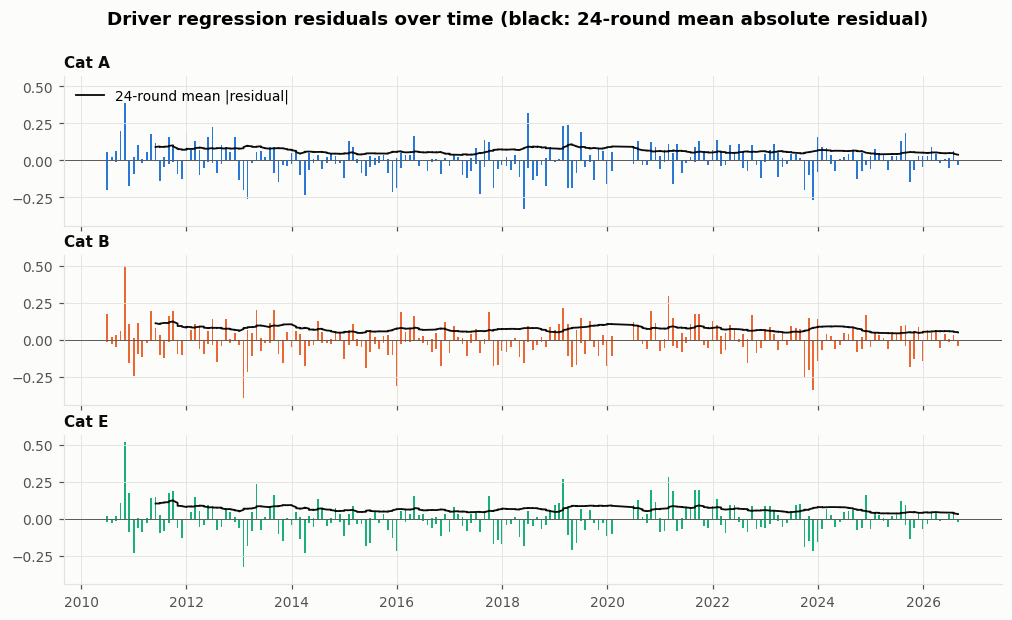

year
2010-20   0.099
2021-26   0.076
Name: resid, dtype: float64


In [7]:
res = data.assign(resid=f_full.resid, date=pd.to_datetime(data.month))
fig, axes = plt.subplots(3, 1, figsize=(11, 6), sharex=True, sharey=True)
for ax, (c, g) in zip(axes, res.groupby("category")):
    ax.bar(g.date, g.resid, width=12, color=CAT_COLORS[c])
    roll = g.set_index("date").resid.abs().rolling(24).mean()
    ax.plot(roll.index, roll, color="#0b0b0b", lw=1.2, label="24-round mean |residual|")
    ax.set_title(f"Cat {c}", loc="left", fontsize=10); ax.axhline(0, color="#52514e", lw=0.6)
axes[0].legend(loc="upper left")
fig.suptitle("Driver regression residuals over time (black: 24-round mean absolute residual)", fontweight="bold")
save(fig, "04_residuals.png"); plt.show()
print(res.groupby(res.year >= 2021).resid.std().rename({False: "2010-20", True: "2021-26"}))

## Effects in dollars

For each feature that is significant at 5% in the full-data model: the change in the expected 2-round rise for a typical move in the feature (one standard deviation; for the bid ratio, the plan's example move from 1.2 to 1.4), in percentage points and in S$ on today's Cat B premium.

In [8]:
pB = feat[(feat.category == "B")].sort_values("t").premium.iloc[-1]
steps = {c: data[c].std() for c in keep}
steps["bid_ratio"] = 0.2
labels = {"bid_ratio": "the bid ratio rises by 0.2 (e.g. 1.2 -> 1.4)", "unsuccessful_share": "the unsuccessful share is +1 s.d.",
          "quota_change_next": "the announced quota to t+2 changes +1 s.d.", "quota_chg_6": "the quota vs a quarter ago is +1 s.d.",
          "mom_2": "the premium has risen 1 s.d. more over the last 2 rounds", "vol_12": "recent volatility is +1 s.d.",
          "e_minus_b": "Cat E's gap over Cat B widens 1 s.d.", "event_down_next": "an announced price-lowering event (COE injection, loan curb, rebate cut) takes effect in the next 2 rounds",
          "event_up_next": "an announced price-raising event (zero growth, loan easing, new rebate) takes effect in the next 2 rounds"}
steps["event_down_next"] = steps["event_up_next"] = 1.0
rows = []
for c in keep:
    b, p = f_full.params[c], f_full.pvalues[c]
    rows.append({"feature": c, "move": labels[c], "step": steps[c], "coef": b, "p_value": p,
                 "effect_pp": b * steps[c] * 100, "effect_sgd_catB": b * steps[c] * pB, "significant": p < 0.05})
eff = pd.DataFrame(rows).sort_values("p_value")
eff.to_csv(PROC / "regression_effects.csv", index=False)
final_tab.to_csv(PROC / "regression_coefficients.csv")
display(eff.round(4))
print(f"Today's Cat B premium: S${pB:,.0f}\n")
for r in eff[eff.significant].itertuples():
    direction = "higher" if r.effect_pp > 0 else "lower"
    print(f"- When {r.move}, the following 2-round rise is on average {abs(r.effect_pp):.2f} percentage points {direction}, "
          f"about S${abs(r.effect_sgd_catB):,.0f} {direction} on a Cat B COE of S${pB:,.0f} (p = {r.p_value:.3f}).")
if not eff.significant.any():
    print("No feature is significant at 5%.")

,feature,move,step,coef,p_value,effect_pp,effect_sgd_catB,significant
6,event_down_next,an announced price-lowering event (COE injecti...,1.000,-0.043,0.003,-4.307,"-5,680.500",True
3,mom_2,the premium has risen 1 s.d. more over the las...,0.093,-0.083,0.030,-0.765,"-1,009.446",True
2,quota_chg_6,the quota vs a quarter ago is +1 s.d.,0.157,-0.034,0.139,-0.532,-701.280,False
0,bid_ratio,the bid ratio rises by 0.2 (e.g. 1.2 -> 1.4),0.200,0.017,0.189,0.337,443.865,False
5,e_minus_b,Cat E's gap over Cat B widens 1 s.d.,0.034,0.120,0.259,0.404,532.960,False
7,event_up_next,"an announced price-raising event (zero growth,...",1.000,-0.021,0.519,-2.084,"-2,749.441",False
4,vol_12,recent volatility is +1 s.d.,0.030,0.057,0.631,0.170,223.808,False
1,quota_change_next,the announced quota to t+2 changes +1 s.d.,0.038,0.019,0.811,0.072,95.162,False


Today's Cat B premium: S$131,901

- When an announced price-lowering event (COE injection, loan curb, rebate cut) takes effect in the next 2 rounds, the following 2-round rise is on average 4.31 percentage points lower, about S$5,680 lower on a Cat B COE of S$131,901 (p = 0.003).
- When the premium has risen 1 s.d. more over the last 2 rounds, the following 2-round rise is on average 0.77 percentage points lower, about S$1,009 lower on a Cat B COE of S$131,901 (p = 0.030).
